Descriptive Statistics & Univariate Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df=pd.read_excel("/content/cleaned_sales_dataset.xlsx")

In [7]:
# Numerical summary
print(df.describe())

                       Order_Date          Age     Quantity    Unit_Price  \
count                        1000  1000.000000  1000.000000   1000.000000   
mean   2025-07-03 11:19:40.800000    41.404000     5.435000  25486.783410   
min           2025-01-01 00:00:00    18.000000     1.000000    145.780000   
25%           2025-03-30 18:00:00    30.000000     3.000000  13895.722500   
50%           2025-07-01 00:00:00    41.000000     5.000000  25398.740000   
75%           2025-10-07 06:00:00    54.000000     8.000000  37512.382500   
max           2026-01-01 00:00:00    65.000000    10.000000  49997.530000   
std                           NaN    13.865101     2.838632  14179.402361   

         Total_Sales  
count    1000.000000  
mean   139399.439650  
min       437.340000  
25%     47066.632500  
50%    108594.025000  
75%    203722.882500  
max    493677.500000  
std    114100.051546  


In [8]:
# Categorical summary
print(df.describe(include='object'))



         Order_ID Customer_ID Customer_Name Gender   City Product     Category
count        1000        1000          1000   1000   1000    1000         1000
unique        992         947           425      2      9       6            5
top     ORD100050    CUST2515  Customer_359   Male  Patna  Mobile  Electronics
freq            9           3             8    511    135     184          354


In [9]:
# Individual statistics
print("Mean:\n", df.mean(numeric_only=True))
print("Median:\n", df.median(numeric_only=True))
print("Mode:\n", df.mode().iloc[0])

Mean:
 Age                41.40400
Quantity            5.43500
Unit_Price      25486.78341
Total_Sales    139399.43965
dtype: float64
Median:
 Age                41.000
Quantity            5.000
Unit_Price      25398.740
Total_Sales    108594.025
dtype: float64
Mode:
 Order_ID                   ORD100050
Order_Date       2025-04-16 00:00:00
Customer_ID                 CUST2515
Customer_Name           Customer_359
Age                             30.0
Gender                          Male
City                           Patna
Product                       Mobile
Category                 Electronics
Quantity                         4.0
Unit_Price                    145.78
Total_Sales                   437.34
Name: 0, dtype: object


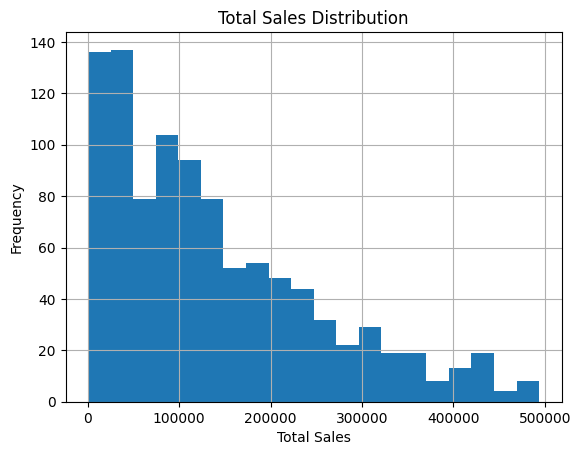

In [11]:
# Histogram
df['Total_Sales'].hist(bins=20)
plt.title("Total Sales Distribution")
plt.xlabel("Total Sales")
plt.ylabel("Frequency")
plt.show()

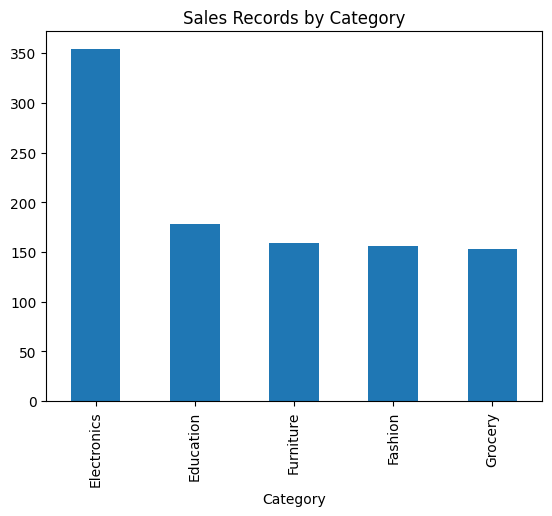

In [12]:
# Bar chart
df['Category'].value_counts().plot(kind='bar')
plt.title("Sales Records by Category")
plt.show()

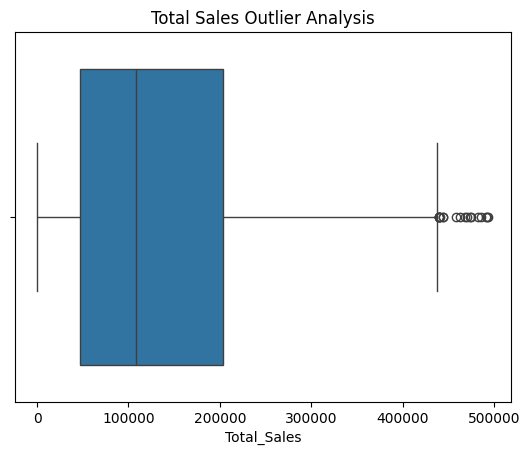

In [13]:
# Box plot
sns.boxplot(x=df['Total_Sales'])
plt.title("Total Sales Outlier Analysis")
plt.show()

Multivariate Analysis & Correlation Analysis


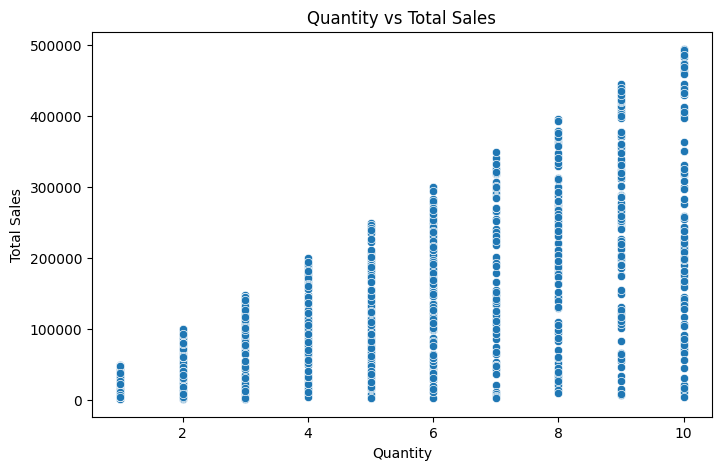

In [14]:
# Quantity vs Total sales

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Quantity',
    y='Total_Sales'
)

plt.title('Quantity vs Total Sales')
plt.xlabel('Quantity')
plt.ylabel('Total Sales')
plt.show()

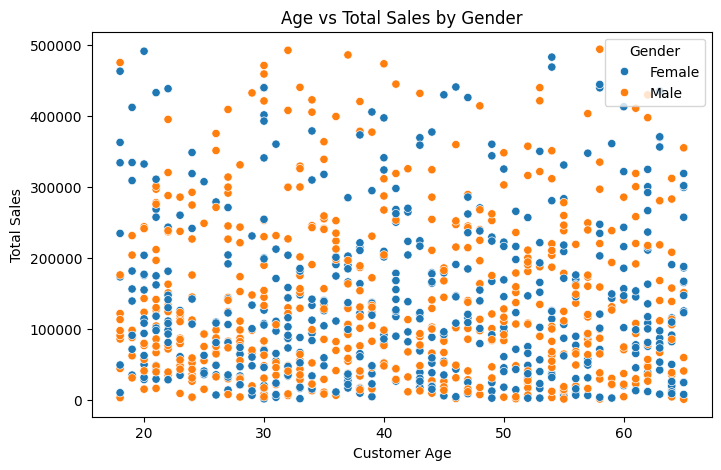

In [15]:
# Age vs Total sales
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Age',
    y='Total_Sales',
    hue='Gender'
)

plt.title('Age vs Total Sales by Gender')
plt.xlabel('Customer Age')
plt.ylabel('Total Sales')
plt.show()

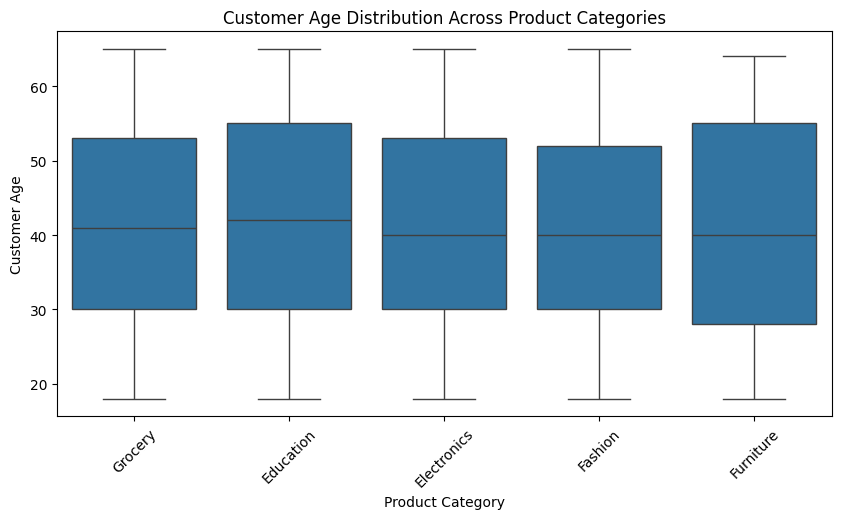

In [16]:
# Age vs Product category
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x='Category',
    y='Age'
)

plt.title('Customer Age Distribution Across Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Customer Age')
plt.xticks(rotation=45)
plt.show()

CORRELATION MATRIX & HEATMAP


In [17]:
numeric_columns = [
    'Age',
    'Quantity',
    'Unit_Price',
    'Total_Sales'
]

correlation_matrix = df[numeric_columns].corr()

print(correlation_matrix)

                  Age  Quantity  Unit_Price  Total_Sales
Age          1.000000 -0.034862   -0.021773    -0.011801
Quantity    -0.034862  1.000000    0.021855     0.646641
Unit_Price  -0.021773  0.021855    1.000000     0.686303
Total_Sales -0.011801  0.646641    0.686303     1.000000


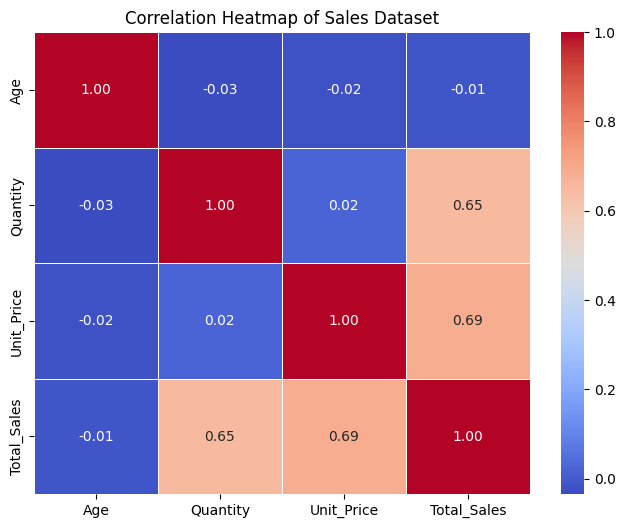

In [18]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Sales Dataset')
plt.show()

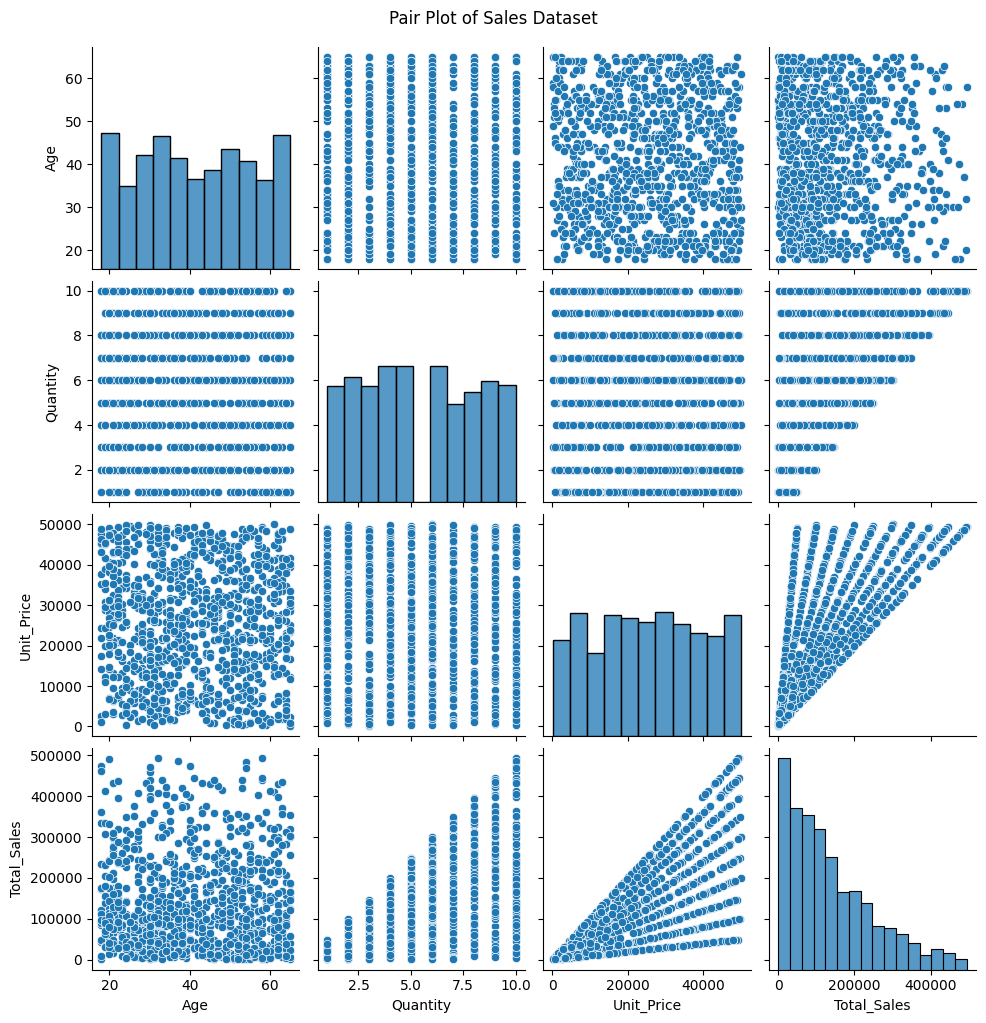

In [19]:
numeric_columns = ['Age', 'Quantity', 'Unit_Price', 'Total_Sales']

sns.pairplot(
    df[numeric_columns],
    diag_kind='hist'
)

plt.suptitle('Pair Plot of Sales Dataset', y=1.02)
plt.show()